<a href="https://colab.research.google.com/github/aashwill/tokens-to-megawatts/blob/main/day1_python_for_capacity_planners.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 1: Python for a capacity planner

**Tokens to Megawatts, Layer 0, Day 1** · about 75 minutes

Today's goal is not to memorize Python. It is to read a short block of Python and say what it does. Everything here uses capacity-planning examples, and every pandas step is shown next to the SQL you already know.

**How to work through it**
1. Run one cell at a time (Shift + Enter). Don't use "Run all".
2. **Before you run a cell, predict what it will print.** That habit is most of the learning.
3. Exercises are marked ✏️. Try them yourself first. Solutions are at the very bottom.

| Part | Topic | Time |
|---|---|---|
| 1 | Python basics: variables, lists, dictionaries, if, loops, functions | 25 min |
| 2 | pandas through SQL: filter, sort, group, join, new columns, a chart | 30 min |
| 3 | Reading an error message | 5 min |
| 4 | The four questions for AI-written code | 10 min |
| 5 | Glossary and wrap-up | 5 min |

---
## Part 1: Python basics

### 1.1 Variables and arithmetic
A variable is a named value. `#` starts a comment, which Python ignores.

In [ ]:
gpus_installed = 1024      # GPUs physically in the cluster
gpus_in_use = 880          # GPUs busy right now

utilization = gpus_in_use / gpus_installed
print(utilization)
print(f"Utilization: {utilization:.1%}")   # f-string: format as a percentage with 1 decimal

0.859375
Utilization: 85.9%


`f"...{value:.1%}"` is an **f-string**. Anything inside `{ }` gets calculated and inserted. You will use these constantly for labels.

✏️ **Exercise 1.** Calculate `headroom_gpus` (installed minus in use) and `headroom_pct` (headroom as a share of installed). Print both in one readable sentence.

In [ ]:
# ✏️ Exercise 1: your code here
headroom_gpus = gpus_installed - gpus_in_use
headroom_pct = headroom_gpus / gpus_installed
print(f"headroom_gpus: {headroom_gpus} and headroom_pct: {headroom_pct:.1%}")

headroom_gpus: 144 and headroom_pct: 14.1%


### 1.2 Lists: an ordered sequence
A list holds values in order. Think of it as one column of numbers.

In [ ]:
weekly_demand = [780, 802, 815, 850, 870, 905, 940, 990]   # GPUs in use, 8 weeks

print(len(weekly_demand))     # how many weeks
print(weekly_demand[0])       # first week (Python counts from 0)
print(weekly_demand[-1])      # last week
print(weekly_demand[-4:])     # last 4 weeks ("slicing")
print(max(weekly_demand), sum(weekly_demand) / len(weekly_demand))   # peak and average

8
780
990
[870, 905, 940, 990]
990 869.0


### 1.3 Dictionaries: named values
A dictionary maps a **key** to a **value**, like one row of a lookup table. This one describes a GPU server.

In [ ]:
server_spec = {
    "gpu_type": "H100",
    "gpus_per_server": 8,
    "kw_per_server": 10.2,   # approximate max power of an 8x H100 server
}

print(server_spec["gpus_per_server"])

servers = 990 / server_spec["gpus_per_server"]
it_kw = servers * server_spec["kw_per_server"]
print(f"{servers:.2f} servers draw about {it_kw:,.0f} kW of IT load")

8
123.75 servers draw about 1,262 kW of IT load


That last line is a first taste of **tokens to megawatts**: GPUs → servers → kW. You'll build the full chain in Layer 2.

Notice that 990 / 8 gave 123.75 servers. You can't buy three-quarters of a server, and Exercise 2 fixes that.

### 1.4 If statements: decisions
Indentation (4 spaces) shows which lines belong to the `if`. Python cares about indentation. It isn't just style.

In [ ]:
threshold = 0.85

if utilization > threshold:
    print("At risk: above the 85% planning threshold")
elif utilization > 0.70:
    print("Healthy")
else:
    print("Under-used: capacity may be stranded")

At risk: above the 85% planning threshold


### 1.5 Loops: do something for every item

In [ ]:
supply = 1024

for week, demand in enumerate(weekly_demand, start=1):
    util = demand / supply
    flag = "⚠️" if util > threshold else ""
    print(f"Week {week}: {demand} GPUs, {util:.0%} {flag}")

Week 1: 780 GPUs, 76% 
Week 2: 802 GPUs, 78% 
Week 3: 815 GPUs, 80% 
Week 4: 850 GPUs, 83% 
Week 5: 870 GPUs, 85% 
Week 6: 905 GPUs, 88% ⚠️
Week 7: 940 GPUs, 92% ⚠️
Week 8: 990 GPUs, 97% ⚠️


`enumerate` hands you a counter alongside each item. Loops are useful, but in pandas (Part 2) you'll rarely need them: pandas does the whole column at once, just like SQL.

### 1.6 Functions: reusable logic
A function takes inputs, does work, and `return`s an output. Most of your simulator will be small functions like this.

In [ ]:
def utilization_of(demand, supply):
    """Share of supply in use."""
    return demand / supply

print(utilization_of(870, 1024))
print(utilization_of(demand=990, supply=1024))   # naming the inputs makes it clearer

0.849609375
0.966796875


✏️ **Exercise 2.** Write a function `servers_needed(gpus, gpus_per_server=8)` that returns how many **whole** servers you need. Hint: `import math`, then `math.ceil` rounds up. Test it: 990 GPUs should need 124 servers, and 1,000 GPUs should need 125.

In [ ]:
# ✏️ Exercise 2: your code here

def servers_needed(gpus, gpus_per_server=8):
    return gpus // gpus_per_server + (gpus % gpus_per_server > 0)

print(servers_needed(990), servers_needed(1000))

124 125


---
## Part 2: pandas through SQL

A pandas **DataFrame** is a table in memory. Here's the mapping you'll use all week:

| SQL | pandas |
|---|---|
| `SELECT * ... LIMIT 5` | `df.head()` |
| `WHERE region = 'us-east'` | `df[df["region"] == "us-east"]` |
| `ORDER BY demand DESC` | `df.sort_values("demand", ascending=False)` |
| `GROUP BY region` + `SUM()` | `df.groupby("region")["demand"].sum()` |
| `JOIN supply USING (region)` | `df.merge(supply, on="region")` |
| `SELECT a / b AS util` | `df["util"] = df["a"] / df["b"]` |

### 2.1 Build a small demand table
This is **synthetic** practice data: 8 weeks × 3 regions × 2 GPU types. From Day 6 on you'll use the real Alibaba trace.

In [ ]:
import pandas as pd
import numpy as np

rng = np.random.default_rng(seed=42)    # fixed seed: same "random" numbers every run

rows = []
base = {"us-east": 400, "eu-west": 250, "asia-south": 150}
for region, start in base.items():
    for gpu_type, share in [("H100", 0.7), ("B200", 0.3)]:
        for week in range(1, 9):
            growth = 1 + 0.03 * week                       # ~3% growth per week
            noise = rng.normal(1, 0.04)                    # +/- 4% weekly wobble
            rows.append({
                "week": week,
                "region": region,
                "gpu_type": gpu_type,
                "gpus_in_use": round(start * share * growth * noise),
            })

demand = pd.DataFrame(rows)
demand.head()          # SELECT * LIMIT 5

,week,region,gpu_type,gpus_in_use
0,1,us-east,H100,292
1,2,us-east,H100,284
2,3,us-east,H100,314
3,4,us-east,H100,325
4,5,us-east,H100,297


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=demand)

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=demand)

https://docs.google.com/spreadsheets/d/1oPt3H86WVnEFKBZ0BPfBRmG4d0Mpi0B2Zxp15yP6zds/edit#gid=0


In [ ]:
print(demand.shape)    # (rows, columns)
demand.dtypes          # column types

(48, 4)


,0
week,int64
region,object
gpu_type,object
gpus_in_use,int64


### 2.2 Filter (WHERE) and sort (ORDER BY)

In [ ]:
us_h100 = demand[(demand["region"] == "us-east") & (demand["gpu_type"] == "H100")]
us_h100.sort_values("gpus_in_use", ascending=False).head(3)

,week,region,gpu_type,gpus_in_use
7,8,us-east,H100,343
6,7,us-east,H100,341
3,4,us-east,H100,325


Use `&` for AND and `|` for OR, and put each condition in its own parentheses. Forgetting the parentheses is the most common beginner error.

✏️ **Exercise 3.** Show all **B200** rows from **week 8**, sorted by `gpus_in_use`, largest first.

In [ ]:
ex = demand[(demand["gpu_type"] == "B200") & (demand["week"] == 8)]
ex.sort_values("gpus_in_use", ascending=False)

,week,region,gpu_type,gpus_in_use
15,8,us-east,B200,144
31,8,eu-west,B200,91
47,8,asia-south,B200,56


In [ ]:
by_region_week = (
    demand.groupby(["region", "week"], as_index=False)["gpus_in_use"]
          .sum()
)
by_region_week.head()

,region,week,gpus_in_use
0,asia-south,1,154
1,asia-south,2,157
2,asia-south,3,165
3,asia-south,4,174
4,asia-south,5,172


`as_index=False` keeps `region` and `week` as normal columns, so the result looks like a SQL result set. The brackets around the whole chain let you split it across lines for readability.

### 2.4 Join a supply table (JOIN)

In [ ]:
supply = pd.DataFrame({
    "region": ["us-east", "eu-west", "asia-south"],
    "gpus_installed": [560, 330, 230],
})

plan = by_region_week.merge(supply, on="region", how="left")   # LEFT JOIN
plan.head()

,region,week,gpus_in_use,gpus_installed
0,asia-south,1,154,230
1,asia-south,2,157,230
2,asia-south,3,165,230
3,asia-south,4,174,230
4,asia-south,5,172,230


### 2.5 New columns: utilization, headroom, risk flag

In [ ]:
plan["utilization"] = plan["gpus_in_use"] / plan["gpus_installed"]
plan["headroom_gpus"] = plan["gpus_installed"] - plan["gpus_in_use"]
plan["at_risk"] = plan["utilization"] > 0.85

plan[plan["week"] == 8]

,region,week,gpus_in_use,gpus_installed,utilization,headroom_gpus,at_risk
7,asia-south,8,190,230,0.826087,40,False
15,eu-west,8,307,330,0.930303,23,True
23,us-east,8,487,560,0.869643,73,True


✏️ **Exercise 4.** For each region, find the **first week** utilization goes above 85%. That's your first, very rough **run-out signal**. Hint: filter to `at_risk`, then `groupby("region")["week"].min()`. Which region crosses first?

In [ ]:
# ✏️ Exercise 4: your code here
first_risk_week = plan[plan["at_risk"]].groupby("region")["week"].min().sort_values()
first_risk_week

,week
region,
eu-west,4
us-east,7


### 2.6 A first capacity chart

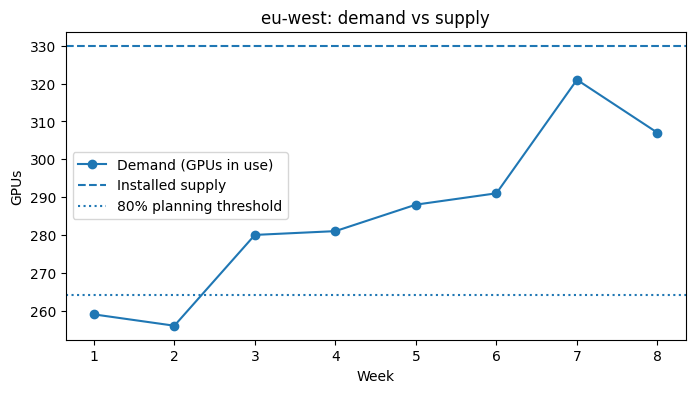

In [ ]:
import matplotlib.pyplot as plt

r = plan[plan["region"] == "eu-west"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(r["week"], r["gpus_in_use"], marker="o", label="Demand (GPUs in use)")
ax.axhline(r["gpus_installed"].iloc[0], linestyle="--", label="Installed supply")
ax.axhline(0.80 * r["gpus_installed"].iloc[0], linestyle=":", label="80% planning threshold")
ax.set_xlabel("Week"); ax.set_ylabel("GPUs"); ax.set_title("eu-west: demand vs supply")
ax.legend(); plt.show()

This is a tiny version of the chart that will lead your README.

✏️ **Exercise 5 (stretch).** Change the code to plot `eu-west` instead. Then change the threshold to 80%. Being able to make small changes like these is the skill this week is about.

### 2.7 Missing values

In [ ]:
messy = plan.copy()
messy.loc[3, "gpus_in_use"] = np.nan        # pretend one week's telemetry is missing

print(messy["gpus_in_use"].isna().sum(), "missing value(s)")
messy["gpus_in_use"] = messy["gpus_in_use"].ffill()   # carry the last known value forward
print(messy["gpus_in_use"].isna().sum(), "missing after forward-fill")

1 missing value(s)
0 missing after forward-fill


Forward-fill is a **planning choice**, not just a coding one: it assumes demand didn't change that week. Real traces have gaps, and saying how you handled them is a good interview answer.

---
## Part 3: Reading an error message

The next cell is **meant to fail**. Run it and read the error from the **bottom up**: the last line names the problem, and the lines above it show where it happened.

In [ ]:
plan.columns

Index(['region', 'week', 'gpus_in_use', 'gpus_installed'], dtype='object')

In [ ]:
plan["gpu_hours"].sum()

KeyError: 'gpu_hours'

The last line says `KeyError: 'gpu_hours'`, which means there's no column with that name. Check what exists with `plan.columns`. Most beginner errors are a typo, a missing column, or a wrong type.

---
## Part 4: The four questions for AI-written code

Imagine Claude Code wrote this block. Before you run it, answer the four questions in the empty cell below:

1. What is the input?
2. What transformation happens?
3. What is the output?
4. How would I know if the result is wrong?

In [ ]:
peak = (
    demand.groupby(["region", "gpu_type"], as_index=False)["gpus_in_use"]
          .max()
          .rename(columns={"gpus_in_use": "peak_gpus"})
          .sort_values("peak_gpus", ascending=False)
)
peak

,region,gpu_type,peak_gpus
5,us-east,H100,343
3,eu-west,H100,222
4,us-east,B200,148
1,asia-south,H100,134
2,eu-west,B200,99
0,asia-south,B200,56


✏️ **Your answers** (double-click to edit this cell):

1. Input: demand data grouped by region and gpu_type filtered for the maximum gpus_in_use
2. Transformation: gpus_in_use is renamed to peak_gpus
3. Output: peak data is returned in descending order or peak_gpus
4. How I'd spot a wrong result: if order is not descending, or if the maximum Gpus_in_use is not selected correctly

---
## Part 5: Wrap-up

**Add to your `glossary.md` today, in your own words:**
- **GPUs in use / utilization:** share of installed GPUs that are busy
- **Headroom:** installed minus in use; the buffer for spikes and failures
- **Planning threshold:** the utilization level (often 80–85%) that triggers action

**Done today when you can:**
- [ ] Explain the `peak` block above out loud in 30 seconds
- [ ] Write the pandas version of a GROUP BY + JOIN without looking
- [ ] Create your GitHub account and the `tokens-to-megawatts` repo

**Tomorrow (Day 2):** Kaggle Learn *Pandas*, lessons 1–3, plus a short Day 2 notebook on dates and weekly roll-ups.

---
---
## Solutions (try first!)

In [ ]:
# Exercise 1
headroom_gpus = gpus_installed - gpus_in_use
headroom_pct = headroom_gpus / gpus_installed
print(f"Headroom: {headroom_gpus} GPUs ({headroom_pct:.1%} of installed)")

In [ ]:
# Exercise 2
import math

def servers_needed(gpus, gpus_per_server=8):
    return math.ceil(gpus / gpus_per_server)

print(servers_needed(990), servers_needed(1000))   # 124 125

In [ ]:
# Exercise 3
demand[(demand["gpu_type"] == "B200") & (demand["week"] == 8)].sort_values("gpus_in_use", ascending=False)

,week,region,gpu_type,gpus_in_use
15,8,us-east,B200,144
31,8,eu-west,B200,91
47,8,asia-south,B200,56


In [ ]:
# Exercise 4
first_risk_week = plan[plan["at_risk"]].groupby("region")["week"].min().sort_values()
first_risk_week

In [ ]:
# Exercise 5: change "us-east" to "eu-west", and 0.85 to 0.80, in the chart cell